# Week 7 — Advanced Models: Gradient Boosting

**Handbook deliverable:** try Gradient Boosting (XGBoost or LightGBM), perform light
hyperparameter tuning (depth, learning rate, `n_estimators`), and report test metrics.



**Numbering note.** The handbook calls this file `05_advanced_models.ipynb`, but the
`05_` slot in this project is already taken by the Week 6 notebook
(`05_feature_engineering.ipynb`). This file is therefore named
`06_advanced_models.ipynb`. (That means the handbook's Week 8 file, also numbered `06_`,
will need a fresh number later — that is a Week 8 problem, not a Week 7 one.)

**What this notebook does**
1. Loads the Week 6 encoded feature set unchanged — no re-encoding, no new features —
   so the comparison against the Week 6 champion is apples-to-apples.
2. Baselines XGBoost and LightGBM on the **validation** set and keeps the winner.
3. Light-tunes the winner (depth, learning rate, `n_estimators`) on the **validation**
   set only.
4. Evaluates the tuned champion on the **test set once**, and compares it against the
   Week 6 champion.

**Baseline to beat (Week 6, frozen):** Random Forest on the new 44-feature set —
test R² 0.8617, RMSE $369,380, MAPE 13.76%.


## 0. Setup — load the Week 6 feature set

Inputs (same folder layout as Weeks 3–6, folders next to this notebook):
- `output_week6/X_train_enc_v2.npy`, `X_val_enc_v2.npy`, `X_test_enc_v2.npy` — 44 features
  (41 old + `bed_bath_ratio`, `property_age`, `DistrictName`)
- `output_week6/feature_list_v2.csv` — the 44 feature names, in matrix column order
- `output_week3/y_train.npy`, `y_val.npy`, `y_test.npy` — the target, unchanged since Week 3
- `output_week6/rf_new_test_pred.npy`  — Week 6 champion test predictions,
  used only to recompute the baseline; otherwise the frozen Week 6 numbers above are used

Method rule for this notebook: **tune on validation only, test once.** Validation
numbers appear in §1–§2; the test set is touched only in §3. That is stricter than
Weeks 5–6 (which printed test numbers for every model), and it is the reason the
§3 test result can be reported honestly as the champion's performance.


In [1]:
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---- CONFIG: folders live next to this notebook (same layout as Weeks 3-6) ----
WEEK3_DIR = Path('output_week3')
WEEK6_DIR = Path('output_week6')
OUT_DIR = Path('output_week7')
OUT_DIR.mkdir(exist_ok=True)

# Week 6 encoded matrices (44 features) + Week 3 targets
Xtr = np.load(WEEK6_DIR / 'X_train_enc_v2.npy')
Xva = np.load(WEEK6_DIR / 'X_val_enc_v2.npy')
Xte = np.load(WEEK6_DIR / 'X_test_enc_v2.npy')
y_train = np.load(WEEK3_DIR / 'y_train.npy')
y_val = np.load(WEEK3_DIR / 'y_val.npy')
y_test = np.load(WEEK3_DIR / 'y_test.npy')
features = pd.read_csv(WEEK6_DIR / 'feature_list_v2.csv')['feature'].tolist()

print(f'Features: {len(features)}')
print(f'train {Xtr.shape} / val {Xva.shape} / test {Xte.shape}')
assert Xtr.shape[1] == Xva.shape[1] == Xte.shape[1] == len(features)  # 44 in your Week 6 run
assert len(y_train) == len(Xtr) and len(y_val) == len(Xva) and len(y_test) == len(Xte)
assert not np.isnan(Xtr).any() and not np.isnan(Xva).any() and not np.isnan(Xte).any()
print('Residual NaNs: 0 — the Week 6 matrices are used as-is, no re-encoding.')

def mape(y_true, y_pred):
    mask = y_true != 0
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)

def metrics(y_true, y_pred):
    return {'R2': r2_score(y_true, y_pred),
            'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
            'MAE': float(np.mean(np.abs(y_true - y_pred))),
            'MAPE': mape(y_true, y_pred)}

# Week 6 champion baseline: recompute from saved predictions if available,
# otherwise use the frozen Week 6 test numbers.
rf_pred_path = WEEK6_DIR / 'rf_new_test_pred.npy'
if rf_pred_path.exists():
    rf_test = metrics(y_test, np.load(rf_pred_path))
    print('\nWeek 6 champion (RF, new feats) — test, recomputed from saved predictions:')
else:
    rf_test = {'R2': 0.8617, 'RMSE': 369380.0, 'MAE': 179843.0, 'MAPE': 13.7617}
    print('\nWeek 6 champion (RF, new feats) — test, frozen Week 6 numbers '
          '(rf_new_test_pred.npy not found):')
print({k: round(v, 4) for k, v in rf_test.items()})


Features: 44
train (105974, 44) / val (11416, 44) / test (12339, 44)
Residual NaNs: 0 — the Week 6 matrices are used as-is, no re-encoding.

Week 6 champion (RF, new feats) — test, recomputed from saved predictions:
{'R2': 0.8617, 'RMSE': 369380.258, 'MAE': 179842.8192, 'MAPE': 13.7617}


## 1. Baseline Gradient Boosting — XGBoost vs LightGBM (validation only)

One sensible default config each, identical in spirit so the comparison is fair:
- Learning rate 0.10, 500 trees, depth 6.
- XGBoost: `max_depth=6`. LightGBM has no `max_depth` in this config — its depth
  equivalent is `num_leaves=31` (a depth-6 tree has at most 2^6 − 1 = 63 leaves, and
  LightGBM grows leaf-wise, so 31 is the conventional depth-6 analogue).
- Both use `hist` / histogram building, all cores, and the same random seed.

Trees do not need the StandardScaler scaling that the Week 6 matrices carry (it is
harmless for them), so the matrices are used unchanged for a clean comparison.

**Availability guard.** If a library is not installed, its baseline is skipped and the
notebook prints the install command instead of crashing. If neither is installed,
stop here, install, and re-run from this section:
`pip install xgboost lightgbm`


In [2]:
# 1a. Import each library separately so one missing library does not kill the other
try:
    from xgboost import XGBRegressor
    HAVE_XGB = True
    print('XGBoost available, version:', __import__('xgboost').__version__)
except ImportError:
    HAVE_XGB = False
    print('XGBoost NOT installed -> baseline skipped. Install with: pip install xgboost')

try:
    from lightgbm import LGBMRegressor
    HAVE_LGB = True
    print('LightGBM available, version:', __import__('lightgbm').__version__)
except ImportError:
    HAVE_LGB = False
    print('LightGBM NOT installed -> baseline skipped. Install with: pip install lightgbm')

assert HAVE_XGB or HAVE_LGB, 'Neither XGBoost nor LightGBM is installed. Run: pip install xgboost lightgbm'

# 1b. One default config each, evaluated on VALIDATION only (test is untouched until §3)
baselines = {}
if HAVE_XGB:
    baselines['XGBoost'] = XGBRegressor(
        objective='reg:squarederror', tree_method='hist',
        learning_rate=0.10, max_depth=6, n_estimators=500,
        subsample=0.9, colsample_bytree=0.9,
        n_jobs=-1, random_state=RANDOM_STATE)
if HAVE_LGB:
    baselines['LightGBM'] = LGBMRegressor(
        objective='regression', learning_rate=0.10, num_leaves=31, n_estimators=500,
        subsample=0.9, colsample_bytree=0.9,
        n_jobs=-1, random_state=RANDOM_STATE, verbosity=-1)

val_rows = []
for name, model in baselines.items():
    t0 = time.time()
    model.fit(Xtr, y_train)
    m_tr = metrics(y_train, model.predict(Xtr))
    m_va = metrics(y_val, model.predict(Xva))
    val_rows.append({'model': name, 'fit_time_s': round(time.time() - t0, 1), **m_va})
    print(f'{name}: fit {time.time() - t0:.1f}s | '
          f'train R2 {m_tr["R2"]:.4f} | val R2 {m_va["R2"]:.4f}, '
          f'val RMSE ${m_va["RMSE"]:,.0f}, val MAPE {m_va["MAPE"]:.2f}%')

val_tbl = pd.DataFrame(val_rows).set_index('model')
print('\nBaseline (validation only):')
print(val_tbl.round(4).to_string())

# Winner = best validation R2. Ties go to the faster fit (fit_time_s is in the table).
winner_name = val_tbl['R2'].idxmax()
print(f'\nWinner on validation: {winner_name} — only this library is tuned in §2.')


XGBoost available, version: 3.2.0
LightGBM available, version: 4.7.0
XGBoost: fit 1.8s | train R2 0.9483 | val R2 0.8932, val RMSE $310,268, val MAPE 13.36%
LightGBM: fit 4.1s | train R2 0.9378 | val R2 0.8936, val RMSE $309,699, val MAPE 13.71%

Baseline (validation only):
          fit_time_s      R2         RMSE          MAE     MAPE
model                                                          
XGBoost          1.8  0.8932  310267.6674  164405.4783  13.3566
LightGBM         4.1  0.8936  309699.0574  167594.9670  13.7149

Winner on validation: LightGBM — only this library is tuned in §2.


## 2. Light tuning — depth, learning rate, n_estimators (validation only)

Two stages, both scored on validation only:
- **Stage A (6 fits):** depth × learning rate at a fixed 500 trees.
  Depth mapping: XGBoost `max_depth` ∈ {4, 6, 8}; LightGBM `num_leaves` ∈ {15, 31, 63}
  (the leaf-count analogue of depths 4, 6, 8). Learning rate ∈ {0.05, 0.10}.
  The other settings (subsample 0.9, colsample 0.9, seed) stay at the §1 baseline.
- **Stage B (2 fits):** at the best Stage A depth/learning rate, try `n_estimators`
  ∈ {300, 800} to check whether 500 trees was too few or already past the point
  of diminishing returns.

No early stopping is used: with a fixed tree count tuned on validation, the code
stays identical across XGBoost/LightGBM versions (early-stopping APIs changed
between versions). The winner is the config with the best validation R²; if two
configs tie within 0.0005, the simpler one (shallower / fewer trees) is preferred
— that tie-break is applied by eye from the table, not hidden in code.

Expected runtime: gradient boosting on 106k × 44 is fast (histogram building);
the 8 tuning fits should take a few minutes total. If a single fit is very slow,
cut Stage A to learning rate 0.10 only — the depth comparison is the informative part.


In [3]:
# 2a. Stage A: depth x learning rate at n_estimators = 500
def make_model(depth, lr, n_est):
    if winner_name == 'XGBoost':
        return XGBRegressor(objective='reg:squarederror', tree_method='hist',
                            learning_rate=lr, max_depth=depth, n_estimators=n_est,
                            subsample=0.9, colsample_bytree=0.9,
                            n_jobs=-1, random_state=RANDOM_STATE)
    # LightGBM: depth expressed as num_leaves
    return LGBMRegressor(objective='regression', learning_rate=lr,
                         num_leaves={4: 15, 6: 31, 8: 63}[depth], n_estimators=n_est,
                         subsample=0.9, colsample_bytree=0.9,
                         n_jobs=-1, random_state=RANDOM_STATE, verbosity=-1)

tune_rows = []
best = None  # (val_R2, depth, lr, n_est, model)
for depth in [4, 6, 8]:
    for lr in [0.05, 0.10]:
        t0 = time.time()
        model = make_model(depth, lr, 500)
        model.fit(Xtr, y_train)
        m_va = metrics(y_val, model.predict(Xva))
        tune_rows.append({'stage': 'A', 'depth': depth, 'learning_rate': lr,
                          'n_estimators': 500, 'fit_time_s': round(time.time() - t0, 1), **m_va})
        print(f'Stage A — depth {depth}, lr {lr}: val R2 {m_va["R2"]:.4f}, '
              f'val RMSE ${m_va["RMSE"]:,.0f} ({time.time() - t0:.1f}s)')
        if best is None or m_va['R2'] > best[0]:
            best = (m_va['R2'], depth, lr, 500, model)

print(f'\nStage A best: depth {best[1]}, lr {best[2]} (val R2 {best[0]:.4f})')

# 2b. Stage B: n_estimators around the Stage A winner (300 / 800)
_, best_depth, best_lr, _, _ = best
for n_est in [300, 800]:
    t0 = time.time()
    model = make_model(best_depth, best_lr, n_est)
    model.fit(Xtr, y_train)
    m_va = metrics(y_val, model.predict(Xva))
    tune_rows.append({'stage': 'B', 'depth': best_depth, 'learning_rate': best_lr,
                      'n_estimators': n_est, 'fit_time_s': round(time.time() - t0, 1), **m_va})
    print(f'Stage B — depth {best_depth}, lr {best_lr}, n {n_est}: '
          f'val R2 {m_va["R2"]:.4f}, val RMSE ${m_va["RMSE"]:,.0f} ({time.time() - t0:.1f}s)')
    if m_va['R2'] > best[0]:
        best = (m_va['R2'], best_depth, best_lr, n_est, model)

tune_tbl = pd.DataFrame(tune_rows)
print('\nTuning table (validation only, sorted by val R2):')
print(tune_tbl.sort_values('R2', ascending=False).round(4).to_string(index=False))

best_val_r2, best_depth, best_lr, best_n, champion = best
print(f'\nTuned champion: {winner_name}, depth {best_depth}, lr {best_lr}, '
      f'n_estimators {best_n} (val R2 {best_val_r2:.4f})')


Stage A — depth 4, lr 0.05: val R2 0.8638, val RMSE $350,421 (2.1s)
Stage A — depth 4, lr 0.1: val R2 0.8826, val RMSE $325,312 (2.1s)
Stage A — depth 6, lr 0.05: val R2 0.8826, val RMSE $325,371 (4.0s)
Stage A — depth 6, lr 0.1: val R2 0.8936, val RMSE $309,699 (3.9s)
Stage A — depth 8, lr 0.05: val R2 0.8932, val RMSE $310,289 (7.7s)
Stage A — depth 8, lr 0.1: val R2 0.8959, val RMSE $306,349 (7.5s)

Stage A best: depth 8, lr 0.1 (val R2 0.8959)
Stage B — depth 8, lr 0.1, n 300: val R2 0.8919, val RMSE $312,207 (4.6s)
Stage B — depth 8, lr 0.1, n 800: val R2 0.8980, val RMSE $303,191 (11.8s)

Tuning table (validation only, sorted by val R2):
stage  depth  learning_rate  n_estimators  fit_time_s     R2        RMSE         MAE    MAPE
    B      8           0.10           800        11.8 0.8980 303191.0557 158011.4073 12.6693
    A      8           0.10           500         7.5 0.8959 306349.0490 160822.2229 12.9701
    A      6           0.10           500         3.9 0.8936 309699.0

## 3. Test once — tuned champion vs the Week 6 champion

This is the first and only time the test set is scored in this notebook.
The comparison row is the Week 6 champion (Random Forest, new 44-feature set),
recomputed from its saved test predictions when available, otherwise the frozen
Week 6 numbers from §0.

How to read the result:
- If the tuned GBM beats RF-new on test R², it becomes the champion going into
  Week 8 (evaluation expansion).
- If it ties (within ~0.001) or loses, the honest conclusion is that gradient
  boosting did not improve on the tuned forest on this feature set — that is a
  reportable Week 7 result, not a failed notebook. Do not then tune further
  against the test set to force a win; that would be test-set leakage by selection.


In [4]:
# TEST — scored exactly once
pred_test = champion.predict(Xte)
gbm_test = metrics(y_test, pred_test)
test_tbl = pd.DataFrame([
    {'model': 'RF (new feats) — Week 6 champion', **rf_test},
    {'model': f'{winner_name} (tuned) — Week 7', **gbm_test},
]).set_index('model')
print('Test results (scored once):')
print(test_tbl.round(4).to_string())
print(f'\nGBM vs RF-new on test R2: {gbm_test["R2"] - rf_test["R2"]:+.4f} '
      f'(RMSE {gbm_test["RMSE"] - rf_test["RMSE"]:+,.0f})')


Test results (scored once):
                                      R2         RMSE          MAE     MAPE
model                                                                      
RF (new feats) — Week 6 champion  0.8617  369380.2580  179842.8192  13.7617
LightGBM (tuned) — Week 7         0.8911  327782.3745  167600.0428  13.0747

GBM vs RF-new on test R2: +0.0294 (RMSE -41,598)


## 4. Diagnostics — tuned champion, same checks as Weeks 5–6

Identical definitions so the numbers are directly comparable to the Week 5 and
Week 6 diagnostics:
- Median residual (around 0 means unbiased; negative = overprediction).
- Luxury band (>2M): mean residual and mean residual as a % of actual —
  Weeks 5–6 both showed luxury underprediction (~332k / ~324k).
- ±10% hit rate: share of test predictions within 10% of actual (Week 6: 56.8%).
- Feature importance (top 15): for XGBoost this is gain-based
  (`feature_importances_`), for LightGBM split-count-based — either way it is a
  ranking, not a causal statement, and it is not comparable in magnitude to the
  Random Forest importances from Week 6.


Tuned LightGBM — median residual: $8,289 (negative = overprediction)
  luxury (>$2M, 13.6% of test): mean residual $240,637 (6.0% of actual)
  ±10% hit rate: 54.5%

Week 6 champion (RF, new feats) for comparison: median residual +$2,161; luxury mean residual +$323,692; hit rate 56.8%.

Top 15 — tuned LightGBM feature importance:
LivingArea             5315
Latitude               4583
Longitude              4523
LotSizeSquareFeet      4206
StreetNumberNumeric    3991
YearBuilt              3879
PostalCode             2709
City                   2448
MLSAreaMajor           2200
DistrictName           2140
Flooring               1842
AssociationFee         1607
bed_bath_ratio         1299
HighSchoolDistrict     1118
ParkingTotal           1040
  bed_bath_ratio: rank 13/44, importance 1299.0000
  property_age: rank 20/44, importance 419.0000
  DistrictName: rank 10/44, importance 2140.0000


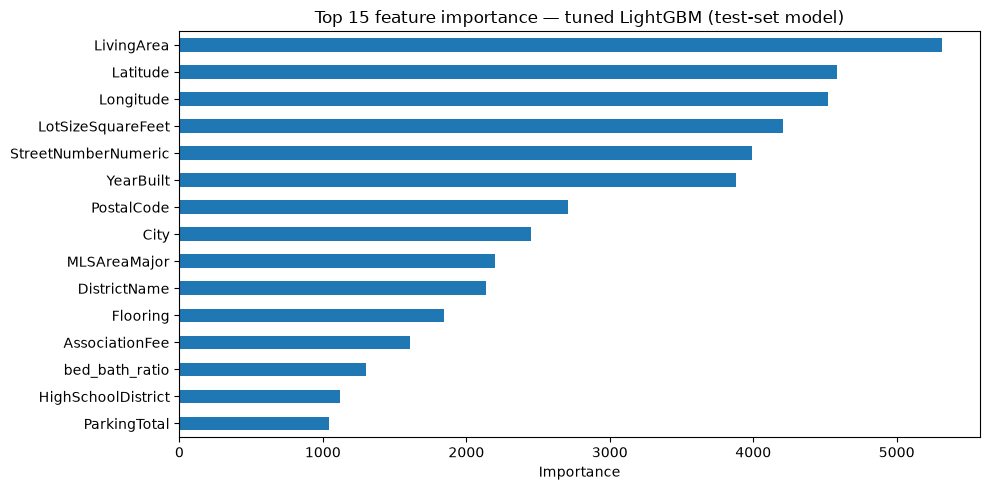

In [5]:
resid = y_test - pred_test
lux = y_test > 2_000_000
hit = np.mean(np.abs(resid) <= 0.10 * y_test) * 100
print(f'Tuned {winner_name} — median residual: ${np.median(resid):,.0f} '
      f'(negative = overprediction)')
print(f'  luxury (>$2M, {lux.mean():.1%} of test): mean residual ${np.mean(resid[lux]):,.0f} '
      f'({np.mean(resid[lux] / y_test[lux]) * 100:.1f}% of actual)')
print(f'  ±10% hit rate: {hit:.1f}%')
print('\nWeek 6 champion (RF, new feats) for comparison: median residual +$2,161; '
      'luxury mean residual +$323,692; hit rate 56.8%.')

imp = pd.Series(champion.feature_importances_, index=features).sort_values(ascending=False)
print(f'\nTop 15 — tuned {winner_name} feature importance:')
print(imp.head(15).round(4).to_string())
for f in ['bed_bath_ratio', 'property_age', 'DistrictName']:
    if f in imp.index:
        rank = int((imp.index == f).argmax()) + 1
        print(f'  {f}: rank {rank}/{len(imp)}, importance {imp[f]:.4f}')
    else:
        print(f'  {f}: not in feature list (check Week 6 feature_list_v2.csv)')

fig, ax = plt.subplots(figsize=(10, 5))
imp.head(15).iloc[::-1].plot.barh(ax=ax)
ax.set_title(f'Top 15 feature importance — tuned {winner_name} (test-set model)')
ax.set_xlabel('Importance')
plt.tight_layout(); plt.show()


## 5. Save artifacts + summary

Saved to `output_week7/`:
- `gbm_tuned.joblib` — the tuned champion (fit on train only, same as scored in §3)
- `gbm_tuned_test_pred.npy` — its test predictions
- `tuning_table_week7.csv` — §2 validation tuning table
- `model_comparison_week7.csv` — §3 test comparison (GBM vs RF-new)
- `week7_summary.txt` — the one-page summary to quote in the Week 10 README

The model is deliberately NOT refit on train + validation after tuning: refitting
would change the model that was just test-scored, so the §3 numbers would no longer
describe the saved model. If you want a train+val refit, that is a separate,
explicitly-labelled model, and it must not inherit the §3 test numbers.


In [6]:
joblib.dump(champion, OUT_DIR / 'gbm_tuned.joblib')
np.save(OUT_DIR / 'gbm_tuned_test_pred.npy', pred_test)
tune_tbl.to_csv(OUT_DIR / 'tuning_table_week7.csv', index=False)
test_tbl.reset_index().to_csv(OUT_DIR / 'model_comparison_week7.csv', index=False)

summary = [
    'Week 7 — Advanced Models: Gradient Boosting (California close-price prediction)',
    f'Date: {pd.Timestamp.now().date()}',
    f'Feature set: Week 6 v2, {len(features)} features (unchanged — no re-encoding, no new features)',
    f'Baseline library comparison (validation): {winner_name} won §1 and was tuned in §2',
    f'Tuned champion: {winner_name}, depth {best_depth}, learning_rate {best_lr}, '
    f'n_estimators {best_n} (val R2 {best_val_r2:.4f})',
    '',
    test_tbl.round(4).to_string(),
    '',
    f'Diagnostics (tuned GBM, test): median residual ${np.median(resid):,.0f}; '
    f'luxury (>$2M) mean residual ${np.mean(resid[lux]):,.0f}; ±10% hit rate {hit:.1f}%.',
    '',
    'Scope: handbook Week 7 only (GBM + light tuning). No outlier handling was applied '
    'to any split, and the test set was scored exactly once (§3).',
]
(OUT_DIR / 'week7_summary.txt').write_text('\n'.join(summary))
print('\n'.join(summary))
print(f'\nsaved -> {OUT_DIR}/ (model, test predictions, tuning + comparison tables, summary)')


Week 7 — Advanced Models: Gradient Boosting (California close-price prediction)
Date: 2026-11-02
Feature set: Week 6 v2, 44 features (unchanged — no re-encoding, no new features)
Baseline library comparison (validation): LightGBM won §1 and was tuned in §2
Tuned champion: LightGBM, depth 8, learning_rate 0.1, n_estimators 800 (val R2 0.8980)

                                      R2         RMSE          MAE     MAPE
model                                                                      
RF (new feats) — Week 6 champion  0.8617  369380.2580  179842.8192  13.7617
LightGBM (tuned) — Week 7         0.8911  327782.3745  167600.0428  13.0747

Diagnostics (tuned GBM, test): median residual $8,289; luxury (>$2M) mean residual $240,637; ±10% hit rate 54.5%.

Scope: handbook Week 7 only (GBM + light tuning). No outlier handling was applied to any split, and the test set was scored exactly once (§3).

saved -> output_week7/ (model, test predictions, tuning + comparison tables, summary)


## 6. What's next — Week 8: Evaluation Expansion

- The handbook Week 8 deliverable is metrics beyond R² (MAPE, MdAPE) and a
  price-band breakdown, plus `metrics_summary.csv`.


